In [1]:
vertices = [(1, "Node 1", 1.0), (2, "Node 2", 1.0), (3, "Node 3", 1.0)]
arcs = [(1, 2, 1.0), (2, 3, 1.0)]
inclusions = [(1, 2), (2, 3)]

with open("/Users/zhangmengqi/Desktop/tmp_network/" + "network.nnf", "w") as f:
    f.write("*Vertices\n")
    for v in vertices:
        f.write(f"{v[0]} \"{v[1]}\" {v[2]}\n")

    f.write("*Arcs\n")
    for a in arcs:
        f.write(f"{a[0]} {a[1]} {a[2]}\n")

    f.write("*Inclusions\n")
    for i in inclusions:
        f.write(f"{i[0]} {i[1]}\n")

In [5]:
import torch
import os

torch_dir = os.path.dirname(torch.__file__)
print(torch_dir)


/Users/zhangmengqi/opt/anaconda3/envs/Scrapper/lib/python3.9/site-packages/torch


In [11]:
import pkgutil
import torch.nn

def list_subpackages(package):
    return [name for _, name, _ in pkgutil.iter_modules(package.__path__)]

print(list_subpackages(torch.nn))

['_reduction', 'backends', 'common_types', 'cpp', 'functional', 'grad', 'init', 'intrinsic', 'modules', 'parallel', 'parameter', 'qat', 'quantizable', 'quantized', 'utils']


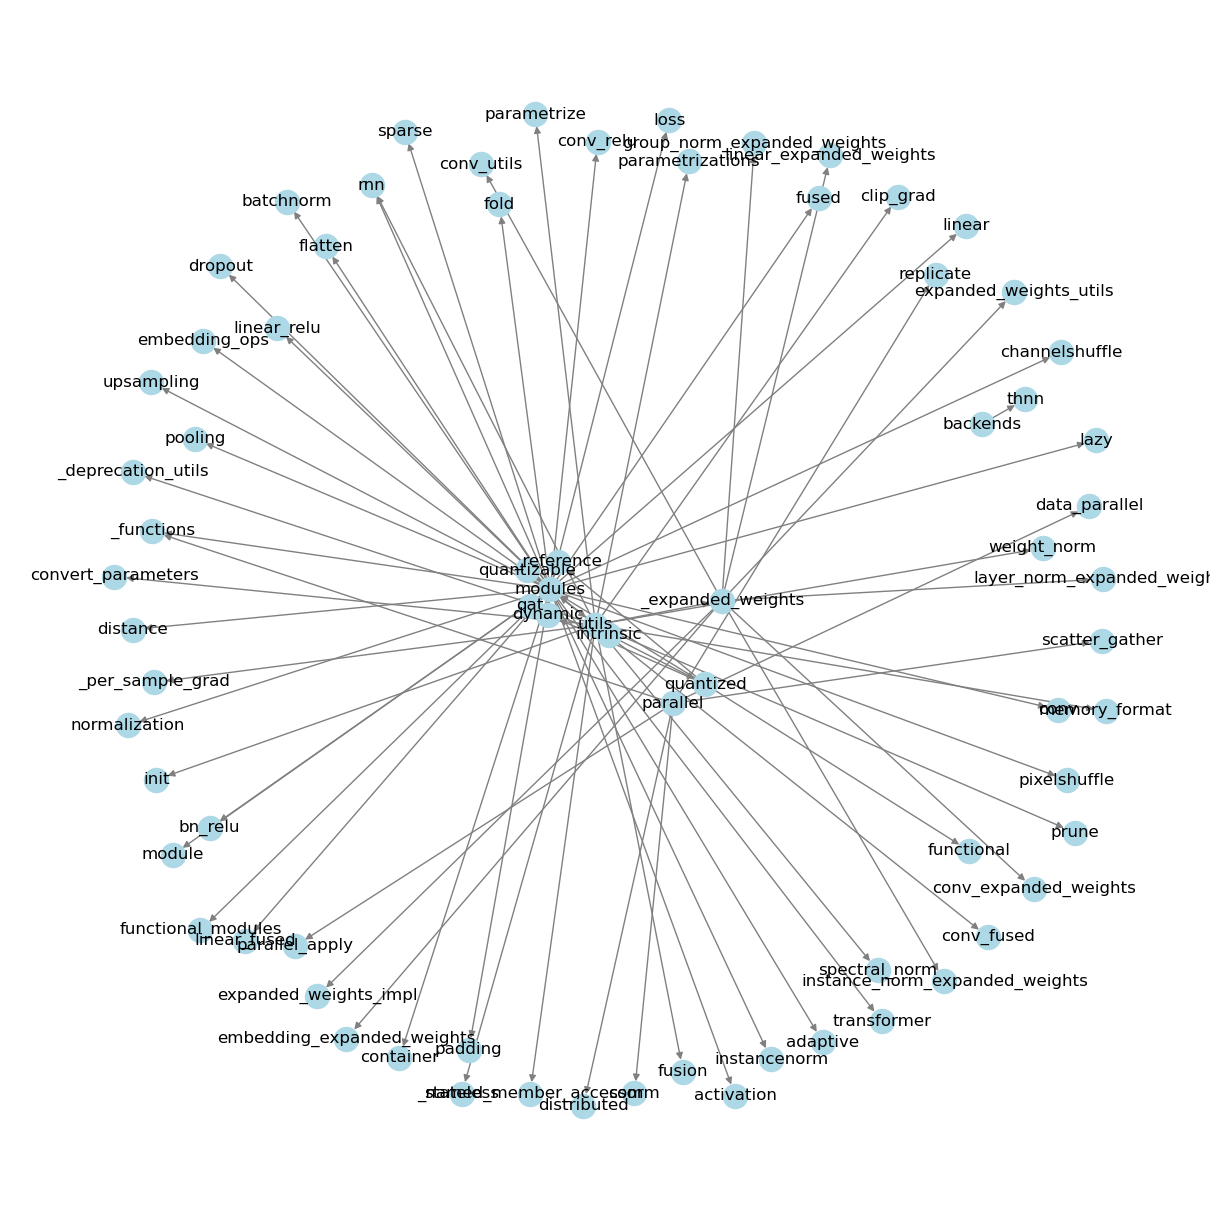

In [10]:
import pkgutil
import torch.nn
import networkx as nx
import matplotlib.pyplot as plt

def add_edges(graph, package, parent=None):
    for _, name, is_pkg in pkgutil.iter_modules(package.__path__):
        if parent:
            graph.add_edge(parent, name)
        if is_pkg:
            add_edges(graph, __import__(f"{package.__name__}.{name}", fromlist=['']), name)

G = nx.DiGraph()
add_edges(G, torch.nn)

plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray')

# Save the figure to the specified path
plt.savefig('/Users/zhangmengqi/Desktop/tmp_network.png')

In [1]:
import pkgutil
import torch.nn
from pyvis.network import Network
from openpyxl import Workbook

# Counters for packages and modules
package_count = 1  # Start with 1 to include torch.nn
module_count = 0

def add_edges(graph, package, parent=None, ws=None):
    global package_count
    global module_count
    for _, name, is_pkg in pkgutil.iter_modules(package.__path__):
        full_name = f"{parent}.{name}" if parent else name
        # Add nodes and edge
        graph.add_node(full_name, color='pink' if is_pkg else 'lightblue')
        if parent:
            graph.add_edge(parent, full_name, arrows='to')
        if is_pkg:
            package_count += 1
            add_edges(graph, __import__(f"{package.__name__}.{name}", fromlist=['']), full_name, ws)
        else:
            module_count += 1
        # Write the node name to the Excel file
        ws.append([full_name])

# Create a new Network instance with height of 1000px
G = Network(height='1300px')

# Add torch.nn as a parent node
G.add_node('torch.nn', color='lightcoral')

# Create a new Excel workbook and get the active worksheet
wb = Workbook()
ws = wb.active
ws.append(['Node Name'])  # Add column name

add_edges(G, torch.nn, 'torch.nn', ws)

# Save the interactive graph to the specified path
G.save_graph('/Users/zhangmengqi/Desktop/tmp_network/torch_nn.html')

# Save the Excel file
wb.save('/Users/zhangmengqi/Desktop/tmp_network/list_sub_modules.xlsx')

# Print the counts
print(f"Number of packages: {package_count}")
print(f"Number of modules: {module_count}")

Number of packages: 26
Number of modules: 97


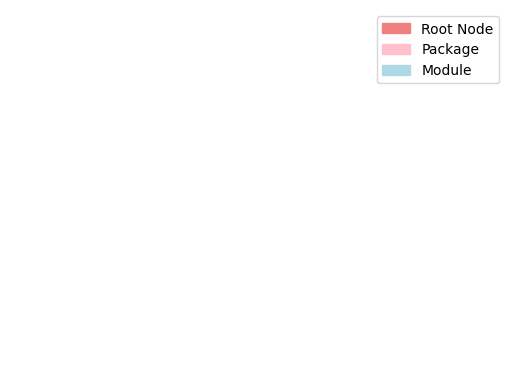

In [51]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

# Create legend
root_patch = mpatches.Patch(color='lightcoral', label='Root Node')
package_patch = mpatches.Patch(color='pink', label='Package')
module_patch = mpatches.Patch(color='lightblue', label='Module')
plt.legend(handles=[root_patch, package_patch, module_patch])

plt.axis('off')
plt.show()

In [4]:
import ast
import pkgutil
import torch.nn
from openpyxl import Workbook

def print_imports(package, parent=None, ws=None):
    for _, name, is_pkg in pkgutil.iter_modules(package.__path__):
        full_name = f"{parent}.{name}" if parent else name
        if is_pkg:
            print_imports(__import__(f"{package.__name__}.{name}", fromlist=['']), full_name, ws)
        else:
            # Parse the source code and print import statements
            source = pkgutil.get_data(package.__name__, f"{name}.py").decode()
            for node in ast.parse(source).body:
                if isinstance(node, ast.Import):
                    for alias in node.names:
                        if alias.name.startswith('torch.nn'):
                            ws.append([f"import {alias.name}", alias.name, full_name, 'valid absolute import'])
                        else:
                            ws.append([f"import {alias.name}", alias.name, full_name, 'importing modules not in torch.nn'])
                elif isinstance(node, ast.ImportFrom):
                    for alias in node.names:
                        if node.level > 0:  # This is a relative import
                            ws.append([f"from . import {alias.name}", f"{parent}.{alias.name}", full_name, 'relative import'])
                        elif node.module and node.module.startswith('torch.nn'):
                            imported_module_full_name = f"{node.module}.{alias.name}" if node.module else alias.name
                            ws.append([f"from {node.module if node.module else ''} import {alias.name}", imported_module_full_name, full_name, 'valid absolute import'])
                        else:
                            imported_module_full_name = f"{node.module}.{alias.name}" if node.module else alias.name
                            ws.append([f"from {node.module if node.module else ''} import {alias.name}", imported_module_full_name, full_name, 'importing modules not in torch.nn'])

wb = Workbook()
ws = wb.active
ws.append(['Import Statement', 'Imported Module Full Name', 'Module Name', 'Notes'])  # Add column names
print_imports(torch.nn, 'torch.nn', ws)
wb.save('/Users/zhangmengqi/Desktop/tmp_network/import_commads.xlsx')

In [ ]:
# generate a list of all modules and sub-packages in torch.nn to a .xlsx file

